In [9]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

BASE = '/content/drive/MyDrive/turbofan-rul/'
DATA = BASE + 'data/'
RESULTS = BASE + 'results/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import glob
print(glob.glob('/content/drive/MyDrive/**/train_FD001*', recursive=True))

['/content/drive/MyDrive/turbofan-rul/data/train_FD001.txt']


In [11]:
print(os.path.exists(DATA + 'train_FD001.txt'))

True


In [12]:
train = pd.read_csv(DATA + 'train_FD001.txt', sep=r'\s+', header=None)
print(train.shape)

(20631, 26)


In [13]:
cols = ['engine', 'cycle', 'setting1', 'setting2', 'setting3'] + [f's{i}' for i in range(1, 22)]
train.columns = cols
train.head()

,engine,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [14]:
print('Rows:', len(train))
print('Engines:', train['engine'].nunique())
print('Missing values:', train.isna().sum().sum())

life = train.groupby('engine')['cycle'].max()
print(life.describe())

Rows: 20631
Engines: 100
Missing values: 0
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


In [15]:
train['max_cycle'] = train.groupby('engine')['cycle'].transform('max')
train['RUL'] = train['max_cycle'] - train['cycle']
train['RUL_capped'] = train['RUL'].clip(upper=125)

train[train['engine'] == 1][['engine', 'cycle', 'RUL', 'RUL_capped']].tail()

,engine,cycle,RUL,RUL_capped
187,1,188,4,4
188,1,189,3,3
189,1,190,2,2
190,1,191,1,1
191,1,192,0,0


In [16]:
sensors = [f's{i}' for i in range(1, 22)]
stds = train[sensors].std().sort_values()
print(stds)

flat = stds[stds < 0.01].index.tolist()
print('Nearly constant sensors:', flat)

s19    0.000000e+00
s18    0.000000e+00
s16    1.556432e-14
s10    4.660829e-13
s5     3.394700e-12
s1     6.537152e-11
s6     1.388985e-03
s15    3.750504e-02
s8     7.098548e-02
s13    7.191892e-02
s21    1.082509e-01
s20    1.807464e-01
s11    2.670874e-01
s2     5.000533e-01
s12    7.375534e-01
s7     8.850923e-01
s17    1.548763e+00
s3     6.131150e+00
s4     9.000605e+00
s14    1.907618e+01
s9     2.208288e+01
dtype: float64
Nearly constant sensors: ['s19', 's18', 's16', 's10', 's5', 's1', 's6']


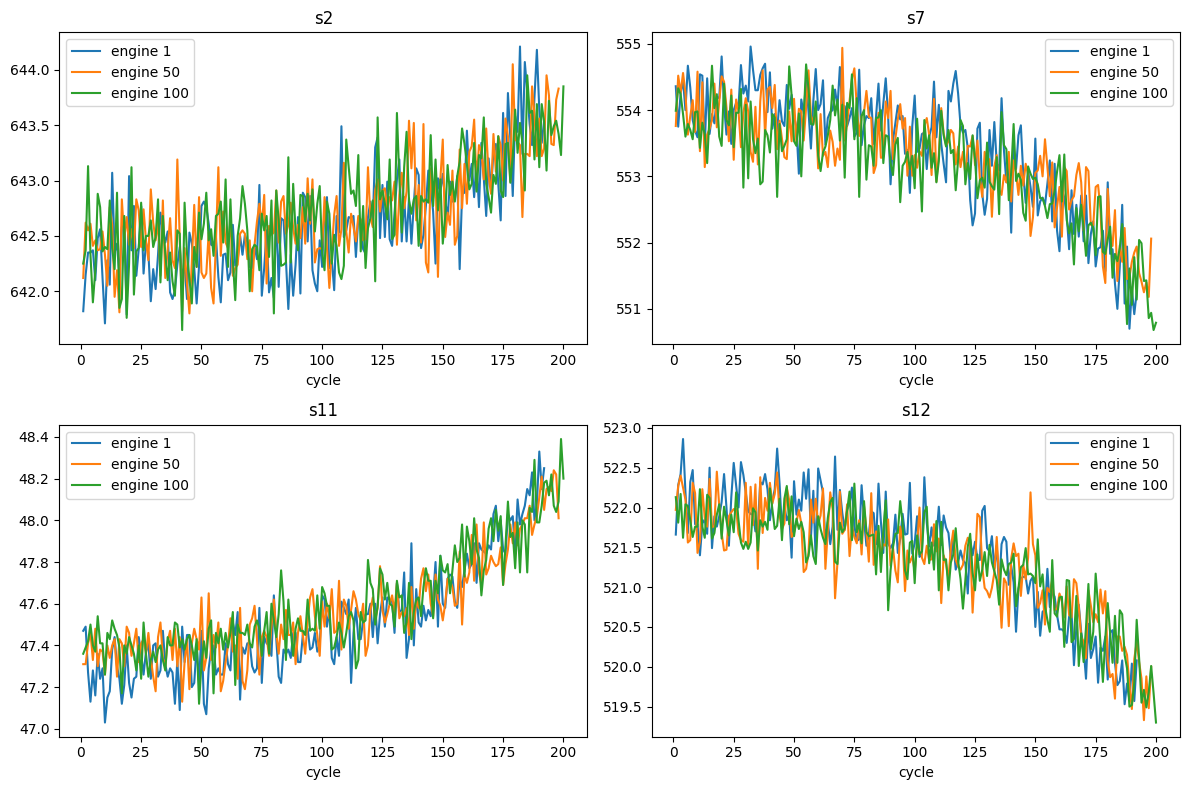

In [17]:
use_sensors = ['s2', 's7', 's11', 's12']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, s in zip(axes.ravel(), use_sensors):
    for e in [1, 50, 100]:
        d = train[train['engine'] == e]
        ax.plot(d['cycle'], d[s], label=f'engine {e}')
    ax.set_title(s)
    ax.set_xlabel('cycle')
    ax.legend()

plt.tight_layout()
os.makedirs(RESULTS, exist_ok=True)
plt.savefig(RESULTS + 'sensor_trends.png', dpi=150)
plt.show()

In [18]:
train.to_csv(DATA + 'train_FD001_clean.csv', index=False)